# 02 — Conversion patterns and uncertainty

This notebook uses the **training split only** for outcome comparisons. It describes associations in the historical session summaries; confidence intervals express sampling uncertainty and are not causal-effect intervals. Groups with fewer than 100 sessions are flagged as low-sample exploratory estimates.

In [1]:
import sys
from pathlib import Path
_base = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(_base))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import ROOT
from src.statistics import wilson_interval, bootstrap_difference

SEED = 42
clean_path = ROOT / 'data' / 'processed' / 'clean_sessions.csv'
split_path = ROOT / 'data' / 'processed' / 'split_assignments.csv'
if not clean_path.exists() or not split_path.exists():
    raise FileNotFoundError('Run Notebook 01 first.')
sessions = pd.read_csv(clean_path).merge(pd.read_csv(split_path), on='row_id')
train = sessions.loc[sessions['split'].eq('train')].copy()
train['Revenue'] = train['Revenue'].astype(bool)
tables = ROOT / 'reports' / 'tables'; figures = ROOT / 'reports' / 'figures'
tables.mkdir(parents=True, exist_ok=True); figures.mkdir(parents=True, exist_ok=True)
overall_n = len(train); overall_purchases = int(train['Revenue'].sum())
overall_rate = train['Revenue'].mean()
print(f'Training sessions: {overall_n:,}; purchases: {overall_purchases:,}; conversion: {overall_rate:.2%}')

Training sessions: 7,397; purchases: 1,144; conversion: 15.47%


## Group summaries and confidence intervals

The helper below reports sample size, purchase count, conversion rate, and a 95% Wilson interval. Wilson intervals behave sensibly for zero and all-purchase groups and are preferable to an unbounded normal approximation for small proportions.

In [2]:
def summarize(group, label):
    n = len(group); purchases = int(group['Revenue'].sum())
    low, high = wilson_interval(purchases, n)
    return {'group': label, 'sessions': n, 'purchases': purchases,
            'conversion_rate': purchases / n, 'ci_low': low, 'ci_high': high,
            'low_sample_flag': n < 100}

def grouped_summary(frame, column, order=None):
    rows = [summarize(group, value) for value, group in frame.groupby(column, observed=True, sort=False)]
    result = pd.DataFrame(rows)
    if order is not None:
        result['order'] = result['group'].map({value: i for i, value in enumerate(order)})
        result = result.sort_values('order').drop(columns='order')
    return result

visitor_table = grouped_summary(train, 'VisitorType')
month_order = [m for m in ['Feb','Mar','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'] if m in train['Month'].unique()]
month_table = grouped_summary(train, 'Month', month_order)
traffic_table = grouped_summary(train, 'TrafficType')
weekend_table = grouped_summary(train, 'Weekend')
visitor_table.to_csv(tables / 'visitor_conversion_training.csv', index=False)
month_table.to_csv(tables / 'month_conversion_training.csv', index=False)
traffic_table.to_csv(tables / 'traffic_conversion_training.csv', index=False)
weekend_table.to_csv(tables / 'weekend_conversion_training.csv', index=False)
display(visitor_table); display(month_table); display(traffic_table); display(weekend_table)

,group,sessions,purchases,conversion_rate,ci_low,ci_high,low_sample_flag
0,Returning_Visitor,6338,886,0.139792,0.131472,0.148547,False
1,New_Visitor,1003,251,0.250249,0.224429,0.277975,False
2,Other,56,7,0.125000,0.061890,0.236257,True


,group,sessions,purchases,conversion_rate,ci_low,ci_high,low_sample_flag
0,Feb,114,2,0.017544,0.004824,0.061719,False
1,Mar,1140,119,0.104386,0.087945,0.123484,False
2,May,2052,221,0.107700,0.095012,0.121854,False
4,Jun,179,17,0.094972,0.060142,0.146822,False
5,Jul,251,40,0.159363,0.119267,0.209728,False
6,Aug,273,45,0.164835,0.125532,0.213440,False
8,Sep,278,53,0.190647,0.148810,0.240918,False
3,Oct,326,71,0.217791,0.176414,0.265743,False
7,Nov,1766,444,0.251416,0.231736,0.272174,False
9,Dec,1018,132,0.129666,0.110414,0.151703,False


,group,sessions,purchases,conversion_rate,ci_low,ci_high,low_sample_flag
0,1,1474,156,0.105834,0.091141,0.122577,False
1,2,2346,506,0.215686,0.199515,0.232788,False
2,3,1245,107,0.085944,0.071620,0.102815,False
3,4,656,95,0.144817,0.119954,0.173816,False
4,6,265,32,0.120755,0.086848,0.165500,False
5,5,158,35,0.221519,0.163809,0.292449,False
6,7,16,5,0.312500,0.141644,0.555961,True
7,8,200,49,0.245000,0.190568,0.309044,False
8,9,24,3,0.125000,0.043443,0.310043,True
9,12,1,0,0.000000,0.000000,0.793457,True


,group,sessions,purchases,conversion_rate,ci_low,ci_high,low_sample_flag
0,False,5679,834,0.146857,0.137889,0.156302,False
1,True,1718,310,0.180442,0.162977,0.199334,False


In [3]:
new = train.loc[train['VisitorType'].eq('New_Visitor'), 'Revenue'].to_numpy(dtype=float)
returning = train.loc[train['VisitorType'].eq('Returning_Visitor'), 'Revenue'].to_numpy(dtype=float)
difference, bootstrap_ci = bootstrap_difference(new, returning, repetitions=2000, seed=SEED)
bootstrap_table = pd.DataFrame([{
    'comparison': 'New_Visitor minus Returning_Visitor',
    'new_sessions': len(new), 'returning_sessions': len(returning),
    'difference_percentage_points': difference * 100,
    'bootstrap_ci_low_percentage_points': bootstrap_ci[0] * 100,
    'bootstrap_ci_high_percentage_points': bootstrap_ci[1] * 100,
    'replicates': 2000, 'seed': SEED
}])
bootstrap_table.to_csv(tables / 'visitor_bootstrap_difference.csv', index=False)
display(bootstrap_table)

,comparison,new_sessions,returning_sessions,difference_percentage_points,bootstrap_ci_low_percentage_points,bootstrap_ci_high_percentage_points,replicates,seed
0,New_Visitor minus Returning_Visitor,1003,6338,11.045752,8.337278,13.695393,2000,42


## Numeric comparisons and training-derived engagement bins

Medians and IQRs are robust summaries for skewed counts and durations. Point-biserial correlation is calculated as an ordinary correlation with the binary target when both variables have finite variance; it can miss nonlinear patterns and should not be interpreted causally.

In [4]:
numeric = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
numeric_rows = []
for column in numeric:
    purchased = train.loc[train['Revenue'], column]
    not_purchased = train.loc[~train['Revenue'], column]
    numeric_rows.append({'feature': column, 'purchase_n': len(purchased), 'purchase_median': purchased.median(), 'purchase_iqr': purchased.quantile(.75)-purchased.quantile(.25), 'nonpurchase_n': len(not_purchased), 'nonpurchase_median': not_purchased.median(), 'nonpurchase_iqr': not_purchased.quantile(.75)-not_purchased.quantile(.25), 'point_biserial_r': train[column].corr(train['Revenue'].astype(float)) if train[column].nunique() > 1 else np.nan})
numeric_table = pd.DataFrame(numeric_rows)
numeric_table.to_csv(tables / 'numeric_target_comparisons_training.csv', index=False)
display(numeric_table)

def engagement_bins(frame, column):
    values = frame[column]
    labels = pd.Series(index=frame.index, dtype='string')
    zero = values.eq(0); labels.loc[zero] = 'zero'
    nonzero = values.loc[~zero]
    if len(nonzero) >= 4:
        quantiles = nonzero.quantile([0, .25, .5, .75, 1]).drop_duplicates().to_numpy()
        if len(quantiles) > 1:
            labels.loc[~zero] = pd.cut(nonzero, bins=quantiles, include_lowest=True, duplicates='drop').astype('string')
    labels = labels.fillna('nonzero')
    return labels

train['ProductRelated_bin'] = engagement_bins(train, 'ProductRelated')
engagement_table = grouped_summary(train.assign(_bin=train['ProductRelated_bin']), '_bin')
engagement_table.to_csv(tables / 'product_engagement_bins_training.csv', index=False)
display(engagement_table)

,feature,purchase_n,purchase_median,purchase_iqr,nonpurchase_n,nonpurchase_median,nonpurchase_iqr,point_biserial_r
0,Administrative,1144,2.000000,5.000000,6253,0.000000,3.000000,0.137330
1,Administrative_Duration,1144,50.500000,150.625000,6253,0.000000,82.600000,0.096085
2,Informational,1144,0.000000,1.000000,6253,0.000000,0.000000,0.080896
3,Informational_Duration,1144,0.000000,18.600000,6253,0.000000,0.000000,0.064462
4,ProductRelated,1144,29.000000,41.250000,6253,16.000000,29.000000,0.157610
5,ProductRelated_Duration,1144,1103.761309,1711.806250,6253,514.000000,1208.116667,0.149675
6,BounceRates,1144,0.000000,0.006375,6253,0.003846,0.020000,-0.149676
7,ExitRates,1144,0.015483,0.015425,6253,0.028283,0.038762,-0.206790
8,PageValues,1144,17.195139,36.881380,6253,0.000000,0.000000,0.493480
9,SpecialDay,1144,0.000000,0.000000,6253,0.000000,0.000000,-0.083162


,group,sessions,purchases,conversion_rate,ci_low,ci_high,low_sample_flag
0,"(0.999, 7.0]",1873,82,0.043780,0.035410,0.054018,False
1,"(7.0, 18.0]",1868,259,0.138651,0.123719,0.155066,False
2,"(18.0, 38.0]",1801,368,0.204331,0.186347,0.223573,False
3,"(38.0, 686.0]",1835,431,0.234877,0.216047,0.254815,False
4,zero,20,4,0.200000,0.080656,0.416022,True


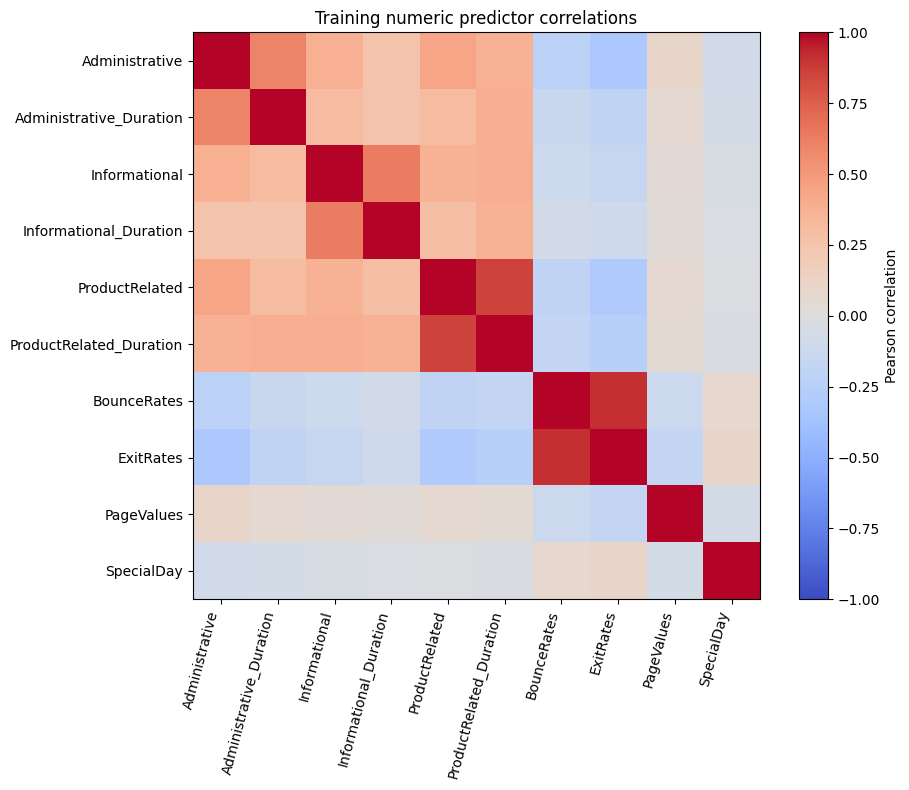

In [5]:
from IPython.display import display
correlation_features = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
correlations = train[correlation_features].corr()
correlations.to_csv(tables / 'numeric_correlation_training.csv')
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_features)), correlation_features, rotation=75, ha='right')
ax.set_yticks(range(len(correlation_features)), correlation_features)
ax.set_title('Training numeric predictor correlations')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout(); fig.savefig(figures / '07_numeric_correlation_heatmap.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

## Required charts

All charts use Matplotlib and are saved at 220 DPI. Error bars show the Wilson intervals where applicable; labels include sample sizes so small groups are visible rather than silently removed.

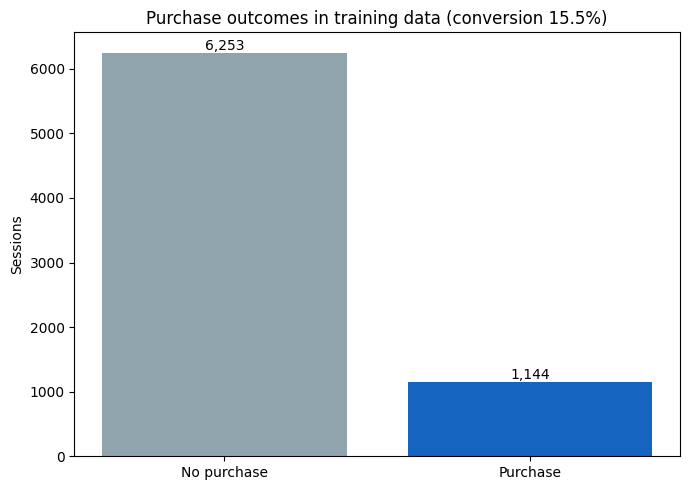

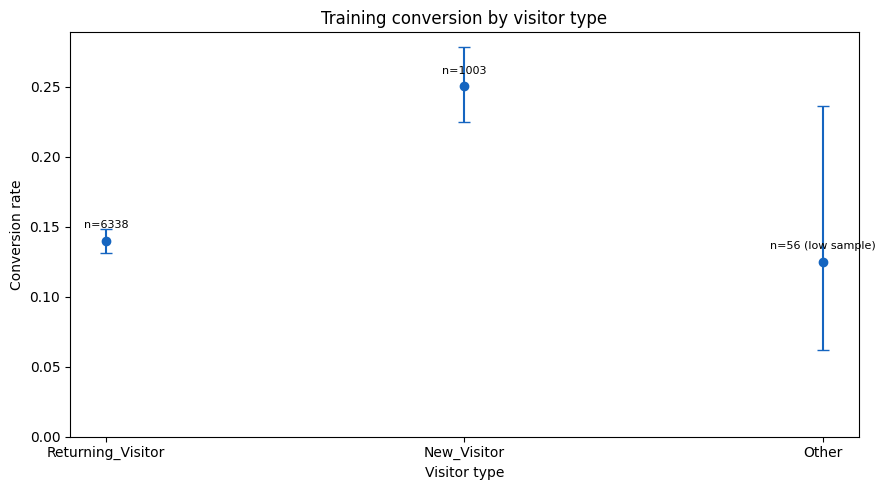

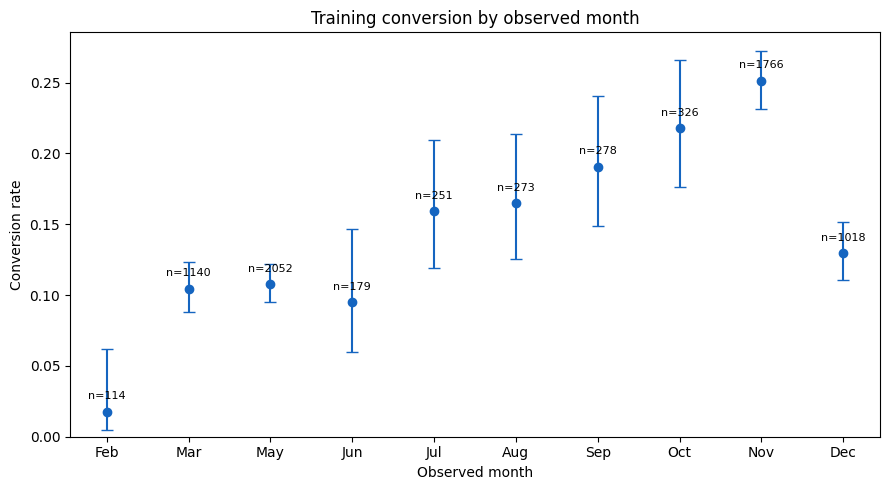

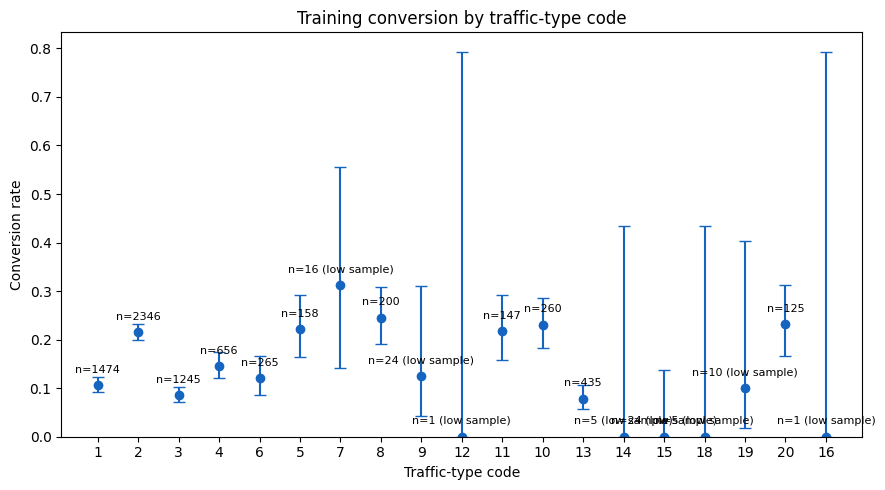

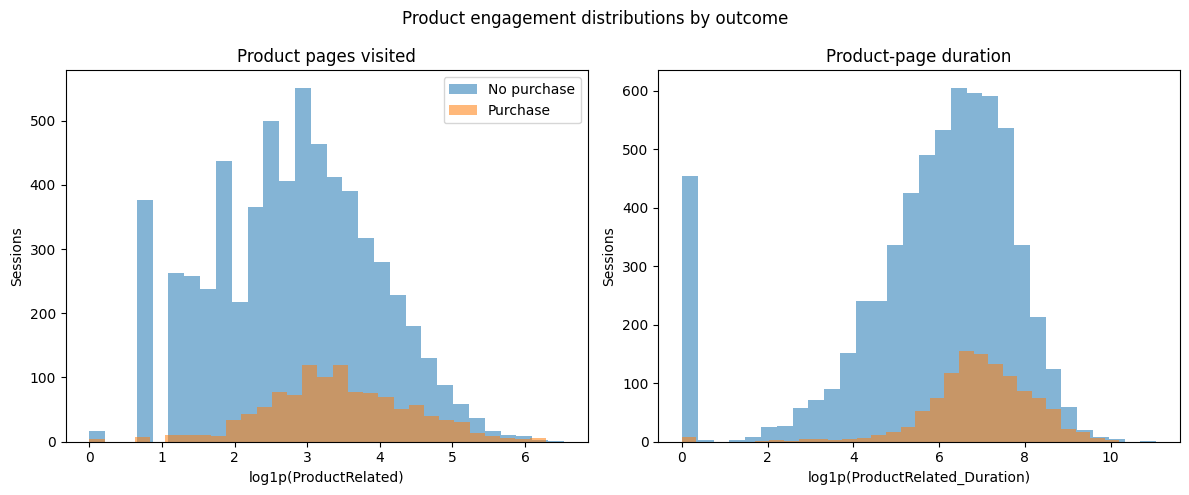

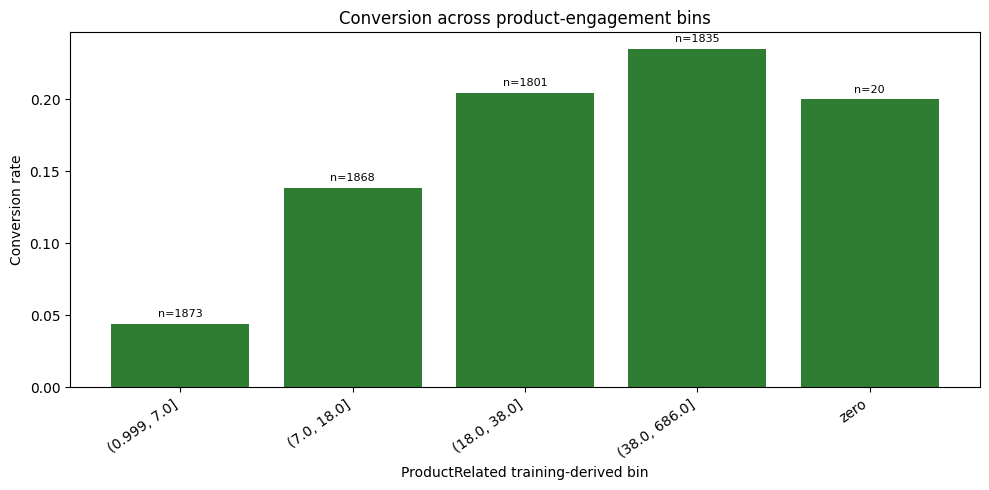

Saved seven Matplotlib figures to reports/figures/.


In [6]:
from IPython.display import display
def interval_plot(table, title, filename, xlabel):
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(table)); rates = table['conversion_rate'].to_numpy()
    yerr = np.vstack([rates - table['ci_low'], table['ci_high'] - rates])
    ax.errorbar(x, rates, yerr=yerr, fmt='o', capsize=4, color='#1565c0')
    ax.set_xticks(x, table['group'].astype(str)); ax.set_ylabel('Conversion rate'); ax.set_xlabel(xlabel)
    ax.set_title(title); ax.set_ylim(bottom=0)
    for i, row in table.reset_index(drop=True).iterrows():
        suffix = ' (low sample)' if row['low_sample_flag'] else ''
        ax.annotate(f"n={int(row['sessions'])}{suffix}", (i, row['conversion_rate']), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=8)
    fig.tight_layout(); fig.savefig(figures / filename, dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

counts = pd.DataFrame({'outcome': ['No purchase', 'Purchase'], 'sessions': [(~train['Revenue']).sum(), train['Revenue'].sum()]})
fig, ax = plt.subplots(figsize=(7, 5)); bars = ax.bar(counts['outcome'], counts['sessions'], color=['#90a4ae', '#1565c0']); ax.set_ylabel('Sessions'); ax.set_title(f'Purchase outcomes in training data (conversion {overall_rate:.1%})')
for bar, value in zip(bars, counts['sessions']): ax.annotate(f'{int(value):,}', (bar.get_x()+bar.get_width()/2, value), ha='center', va='bottom')
fig.tight_layout(); fig.savefig(figures / '01_purchase_outcome_counts.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)
interval_plot(visitor_table, 'Training conversion by visitor type', '02_visitor_conversion_training.png', 'Visitor type')
interval_plot(month_table, 'Training conversion by observed month', '03_month_conversion_training.png', 'Observed month')
interval_plot(traffic_table, 'Training conversion by traffic-type code', '04_traffic_conversion_training.png', 'Traffic-type code')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title in zip(axes, ['ProductRelated', 'ProductRelated_Duration'], ['Product pages visited', 'Product-page duration']):
    for value, group in train.groupby('Revenue', observed=True):
        ax.hist(np.log1p(group[column]), bins=30, alpha=.55, label='Purchase' if value else 'No purchase')
    ax.set_xlabel(f'log1p({column})'); ax.set_ylabel('Sessions'); ax.set_title(title)
axes[0].legend(); fig.suptitle('Product engagement distributions by outcome'); fig.tight_layout(); fig.savefig(figures / '05_product_engagement_distributions.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 5)); x=np.arange(len(engagement_table)); ax.bar(x, engagement_table['conversion_rate'], color='#2e7d32'); ax.set_xticks(x, engagement_table['group'].astype(str), rotation=35, ha='right'); ax.set_ylabel('Conversion rate'); ax.set_xlabel('ProductRelated training-derived bin'); ax.set_title('Conversion across product-engagement bins'); ax.set_ylim(bottom=0)
for i,row in engagement_table.reset_index(drop=True).iterrows(): ax.annotate(f"n={int(row['sessions'])}", (i,row['conversion_rate']), xytext=(0,5), textcoords='offset points', ha='center', fontsize=8)
fig.tight_layout(); fig.savefig(figures / '06_product_engagement_bins.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)
print('Saved seven Matplotlib figures to reports/figures/.')

## Data-driven interpretation

The tables and charts above are the source of the findings below. In this execution, new visitors converted at **25.0%** (251/1,003) and returning visitors at **14.0%** (886/6,338), a bootstrap difference of approximately **11.0 percentage points**. The interval and group sizes should accompany that comparison. The `Other` visitor group is low-sample and has a substantially wider interval, so it is exploratory.

Product engagement, month, traffic type, and rate comparisons are descriptive patterns only. Correlated predictors can make individual relationships look stronger or weaker than the underlying behavior, and a session summary cannot show that increasing a measured behavior would cause a purchase. No validation or test outcomes were used for these comparisons.